In [3]:
import pandas as pd
df = pd.read_csv("student_dropout_dataset_v3.csv")
display(df.head())

,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0


In [4]:
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Shape: (10000, 19)
Rows: 10000
Columns: 19


In [5]:
print(df.columns)

Index(['Student_ID', 'Age', 'Gender', 'Family_Income', 'Internet_Access',
       'Study_Hours_per_Day', 'Attendance_Rate', 'Assignment_Delay_Days',
       'Travel_Time_Minutes', 'Part_Time_Job', 'Scholarship', 'Stress_Index',
       'GPA', 'Semester_GPA', 'CGPA', 'Semester', 'Department',
       'Parental_Education', 'Dropout'],
      dtype='object')


In [6]:
print(df.columns.tolist())

['Student_ID', 'Age', 'Gender', 'Family_Income', 'Internet_Access', 'Study_Hours_per_Day', 'Attendance_Rate', 'Assignment_Delay_Days', 'Travel_Time_Minutes', 'Part_Time_Job', 'Scholarship', 'Stress_Index', 'GPA', 'Semester_GPA', 'CGPA', 'Semester', 'Department', 'Parental_Education', 'Dropout']


In [7]:
print(df.index.tolist())

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221,

In [8]:
print(df.dtypes)

Student_ID                 int64
Age                      float64
Gender                    object
Family_Income            float64
Internet_Access           object
Study_Hours_per_Day      float64
Attendance_Rate          float64
Assignment_Delay_Days      int64
Travel_Time_Minutes      float64
Part_Time_Job             object
Scholarship               object
Stress_Index             float64
GPA                      float64
Semester_GPA             float64
CGPA                     float64
Semester                  object
Department                object
Parental_Education        object
Dropout                    int64
dtype: object


In [9]:
Dropout = df.columns[-1]
print(df[Dropout].value_counts())
print()
print(df[Dropout].value_counts(normalize=True) * 100)

Dropout
0    7646
1    2354
Name: count, dtype: int64

Dropout
0    76.46
1    23.54
Name: proportion, dtype: float64


***Handling Duplicates***

In [10]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())
print(df.shape)

Duplicates before: 0
Duplicates after: 0
(10000, 19)


***Handling Missing Values***

In [11]:
df = df.fillna(df.median(numeric_only=True))
df = df.fillna(df.mode().iloc[0])

print("Missing now:", df.isnull().sum().sum())

Missing now: 0


***Encoding Categorical Data***

In [12]:
df = df.drop(columns=["Student_ID"])

df["Internet_Access"] = df["Internet_Access"].map({"Yes": 1, "No": 0})
df["Part_Time_Job"] = df["Part_Time_Job"].map({"Yes": 1, "No": 0})
df["Scholarship"] = df["Scholarship"].map({"Yes": 1, "No": 0})

df = pd.get_dummies(
    df,
    columns=["Gender", "Department", "Parental_Education"],
    drop_first=True,
    dtype=int
)

print(df.shape)
df.head()

(10000, 23)


,Age,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,...,Semester,Dropout,Gender_Male,Department_Business,Department_CS,Department_Engineering,Department_Science,Parental_Education_High School,Parental_Education_Master,Parental_Education_PhD
0,22.1,25000.0,1,3.36,86.1,2,20.4,1,0,5.5,...,Year 1,0,1,0,0,0,0,1,0,0
1,20.7,25000.0,1,4.30,68.0,2,44.0,0,0,6.8,...,Year 3,1,1,0,0,1,0,0,0,0
2,22.4,40183.0,1,4.40,70.9,0,48.9,1,0,5.5,...,Year 1,0,1,0,0,0,0,0,1,0
3,24.4,29740.5,1,4.00,82.2,2,38.6,0,0,5.5,...,Year 1,1,1,0,1,0,0,1,0,0
4,20.5,25319.0,1,4.19,75.7,1,23.0,0,0,7.0,...,Year 4,0,0,1,0,0,0,0,0,0


***Final Dataset and Feature-Target Separation***

In [13]:
print("Final shape:", df.shape)
print("Missing:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print(df.dtypes)

X = df.drop("Dropout", axis=1)
y = df["Dropout"]

print("X:", X.shape, "y:", y.shape)

df.to_csv("student_dropout_cleaned.csv", index=False)

Final shape: (10000, 23)
Missing: 0
Duplicates: 0
Age                               float64
Family_Income                     float64
Internet_Access                     int64
Study_Hours_per_Day               float64
Attendance_Rate                   float64
Assignment_Delay_Days               int64
Travel_Time_Minutes               float64
Part_Time_Job                       int64
Scholarship                         int64
Stress_Index                      float64
GPA                               float64
Semester_GPA                      float64
CGPA                              float64
Semester                           object
Dropout                             int64
Gender_Male                         int64
Department_Business                 int64
Department_CS                       int64
Department_Engineering              int64
Department_Science                  int64
Parental_Education_High School      int64
Parental_Education_Master           int64
Parental_Education_PhD    

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


KeyboardInterrupt: 

Dropout
0    7646
1    2354
Name: count, dtype: int64


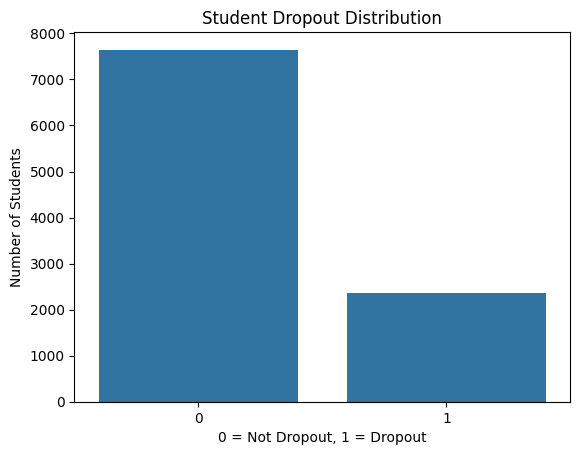

In [15]:
print(df["Dropout"].value_counts())

sns.countplot(data=df, x="Dropout")
plt.title("Student Dropout Distribution")
plt.xlabel("0 = Not Dropout, 1 = Dropout")
plt.ylabel("Number of Students")
plt.show()


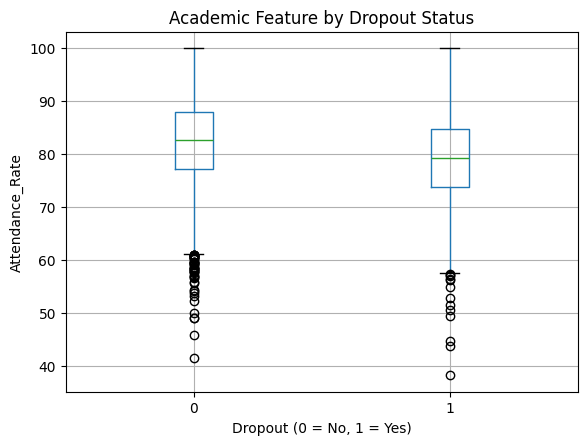

Feature used: Attendance_Rate


In [16]:
df["Dropout"] = pd.to_numeric(df["Dropout"], errors="coerce")

numeric_cols = df.select_dtypes(include="number").columns.tolist()

performance_cols = [
    c for c in numeric_cols
    if any(word in c.lower() for word in
           ["grade", "gpa", "score", "marks", "exam",
            "performance", "academic", "attendance"])
    and c != "Dropout"
]

if not performance_cols:
    performance_cols = [
        c for c in numeric_cols
        if c != "Dropout" and df[c].nunique() > 2
    ]

if performance_cols:
    col = performance_cols[0]

    df.boxplot(column=col, by="Dropout")
    plt.title("Academic Feature by Dropout Status")
    plt.suptitle("")
    plt.xlabel("Dropout (0 = No, 1 = Yes)")
    plt.ylabel(col)
    plt.show()

    print("Feature used:", col)
else:
    print("No numeric performance feature found.")


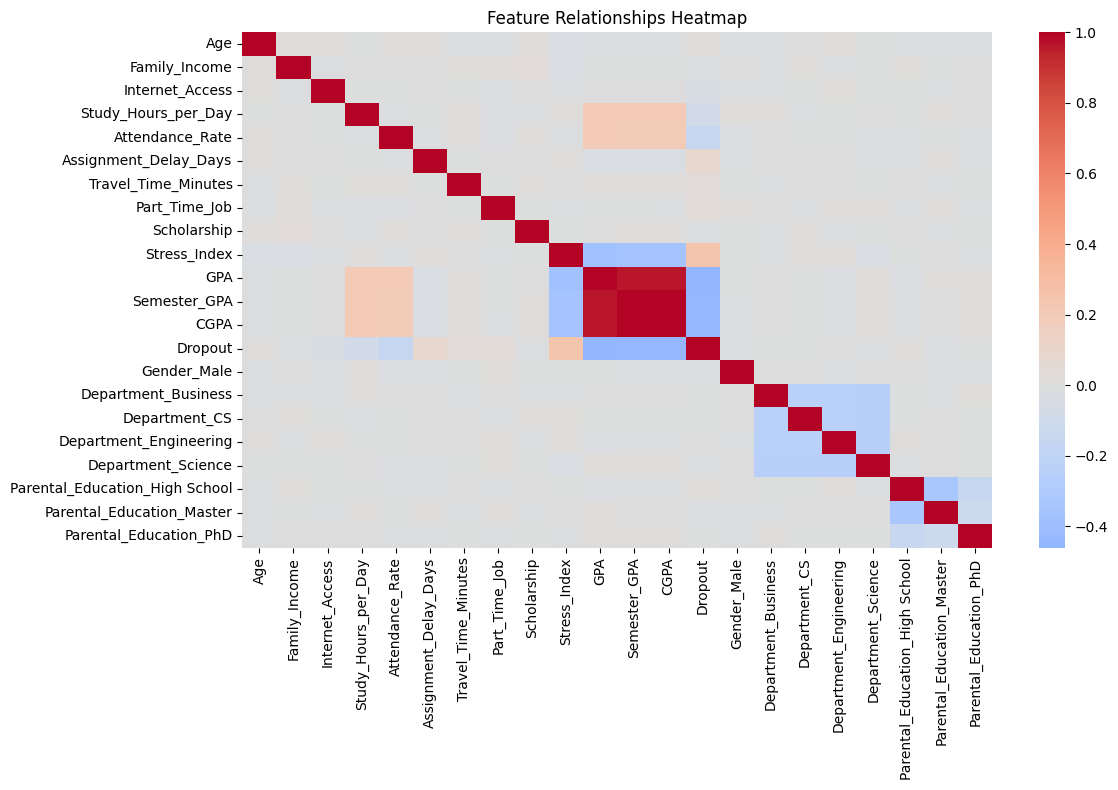

In [17]:
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature Relationships Heatmap")
plt.tight_layout()
plt.show()


In [18]:
print("Dropout rate (%):",
      round(df["Dropout"].mean() * 100, 2))

print("\nAverage feature values by dropout status:")
print(df.groupby("Dropout")[numeric_cols]
        .mean(numeric_only=True).round(2))

print("\nCorrelation with Dropout:")
print(corr["Dropout"].drop("Dropout")
      .sort_values(ascending=False).round(2))


Dropout rate (%): 23.54

Average feature values by dropout status:
           Age  Family_Income  Internet_Access  Study_Hours_per_Day  \
Dropout                                                               
0        21.02       38060.35             0.88                 4.07   
1        21.06       37572.07             0.85                 3.82   

         Attendance_Rate  Assignment_Delay_Days  Travel_Time_Minutes  \
Dropout                                                                
0                  82.48                   1.74                29.99   
1                  79.31                   2.00                30.78   

         Part_Time_Job  Scholarship  Stress_Index  ...  CGPA  Dropout  \
Dropout                                            ...                  
0                 0.39         0.35          5.27  ...  2.56      0.0   
1                 0.43         0.35          6.28  ...  1.44      1.0   

         Gender_Male  Department_Business  Department_CS  \
Dropou

In [19]:
df["Semester"] = df["Semester"].astype(str).str.extract(r"(\d+)").astype(int)

print(df.shape)
print(df["Semester"].value_counts().sort_index())
print(df.dtypes)

(10000, 23)
Semester
1    2455
2    2488
3    2521
4    2536
Name: count, dtype: int64
Age                               float64
Family_Income                     float64
Internet_Access                     int64
Study_Hours_per_Day               float64
Attendance_Rate                   float64
Assignment_Delay_Days               int64
Travel_Time_Minutes               float64
Part_Time_Job                       int64
Scholarship                         int64
Stress_Index                      float64
GPA                               float64
Semester_GPA                      float64
CGPA                              float64
Semester                            int64
Dropout                             int64
Gender_Male                         int64
Department_Business                 int64
Department_CS                       int64
Department_Engineering              int64
Department_Science                  int64
Parental_Education_High School      int64
Parental_Education_Master      

***Train/test split***

In [20]:
from sklearn.model_selection import train_test_split

X = df.drop("Dropout", axis=1)
y = df["Dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print()
print("Train dropout %:", round(y_train.mean() * 100, 2))
print("Test dropout %:", round(y_test.mean() * 100, 2))

X_train: (8000, 22)
X_test : (2000, 22)
y_train: (8000,)
y_test : (2000,)

Train dropout %: 23.54
Test dropout %: 23.55


***Model training***

In [21]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training Accuracy:", round(model.score(X_train, y_train), 4))
print("Testing Accuracy :", round(model.score(X_test, y_test), 4))

Model trained successfully!
Training Accuracy: 0.8117
Testing Accuracy : 0.8145


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


***Predictions***

In [22]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": y_pred[:10]
})
print("First 10 predictions:")
print(results)

First 10 predictions:
   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       0          0
4       1          0
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0


***Prediction probabilities***

In [24]:
y_prob = model.predict_proba(X_test)

prob_df = pd.DataFrame({
    "Prob_Not_Dropout": y_prob[:10, 0].round(4),
    "Prob_Dropout": y_prob[:10, 1].round(4),
    "Predicted": y_pred[:10]
})
print("First 10 prediction probabilities:")
print(prob_df)

First 10 prediction probabilities:
   Prob_Not_Dropout  Prob_Dropout  Predicted
0            0.8940        0.1060          0
1            0.7077        0.2923          0
2            0.9210        0.0790          0
3            0.7316        0.2684          0
4            0.5005        0.4995          0
5            0.9422        0.0578          0
6            0.9809        0.0191          0
7            0.7158        0.2842          0
8            0.6843        0.3157          0
9            0.6266        0.3734          0


***Confusion Matrix***

[[1439   90]
 [ 281  190]]


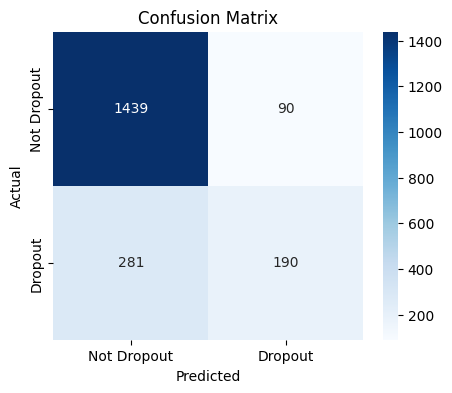

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Dropout", "Dropout"],
            yticklabels=["Not Dropout", "Dropout"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

***Classification report***

In [27]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["Not Dropout", "Dropout"]))

              precision    recall  f1-score   support

 Not Dropout       0.84      0.94      0.89      1529
     Dropout       0.68      0.40      0.51       471

    accuracy                           0.81      2000
   macro avg       0.76      0.67      0.70      2000
weighted avg       0.80      0.81      0.80      2000



***Accuracy, Precision, Recall, F1, ROC-AUC***


In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob[:, 1]), 4))

Accuracy : 0.8145
Precision: 0.6786
Recall   : 0.4034
F1-score : 0.506
ROC-AUC  : 0.8186


***ROC Curve***

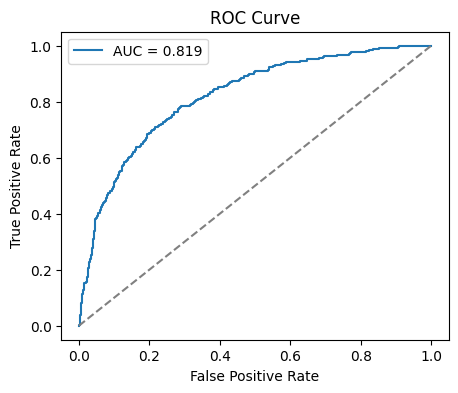

In [29]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_prob[:, 1])
auc = roc_auc_score(y_test, y_prob[:, 1])

plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

***False Positives aur False Negatives***

In [30]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("True Negatives (sahi Not Dropout):", tn)
print("False Positives (Not Dropout ko Dropout bataya):", fp)
print("False Negatives (Dropout ko Not Dropout bataya):", fn)
print("True Positives (sahi Dropout):", tp)

True Negatives (sahi Not Dropout): 1439
False Positives (Not Dropout ko Dropout bataya): 90
False Negatives (Dropout ko Not Dropout bataya): 281
True Positives (sahi Dropout): 190


***Installing Gradaio***

In [33]:
!pip install -q gradio

***Prediction function***

In [34]:
import pandas as pd

def predict_dropout(age, family_income, internet, study_hours, attendance,
                    assign_delay, travel_time, part_time, scholarship, stress,
                    gpa, sem_gpa, cgpa, semester, gender, department, parental_edu):

    # Ek row banao, sab columns 0 se start (training jaisi hi order mein)
    row = pd.DataFrame(0, index=[0], columns=X_train.columns)

    row["Age"] = age
    row["Family_Income"] = family_income
    row["Internet_Access"] = 1 if internet == "Yes" else 0
    row["Study_Hours_per_Day"] = study_hours
    row["Attendance_Rate"] = attendance
    row["Assignment_Delay_Days"] = assign_delay
    row["Travel_Time_Minutes"] = travel_time
    row["Part_Time_Job"] = 1 if part_time == "Yes" else 0
    row["Scholarship"] = 1 if scholarship == "Yes" else 0
    row["Stress_Index"] = stress
    row["GPA"] = gpa
    row["Semester_GPA"] = sem_gpa
    row["CGPA"] = cgpa
    row["Semester"] = int(semester)

    # One-hot columns (Female, Arts, Bachelor drop hue the, unki value 0 hi rehti hai)
    if gender == "Male":
        row["Gender_Male"] = 1
    if department != "Arts":
        row["Department_" + department] = 1
    if parental_edu != "Bachelor":
        row["Parental_Education_" + parental_edu] = 1

    prob = model.predict_proba(row)[0, 1]      # Dropout ki probability

    if prob < 0.30:
        risk = "Low Risk"
    elif prob < 0.60:
        risk = "Medium Risk"
    else:
        risk = "High Risk"

    return f"{prob * 100:.1f}%", risk

***Multiple test cases***

In [35]:
cases = {
    "Case 1 - Strong student": [21, 60000, "Yes", 5.0, 92, 0, 20, "No", "Yes", 3.0, 3.5, 3.4, 3.4, 2, "Female", "CS", "Master"],
    "Case 2 - Average student": [21, 35000, "Yes", 4.0, 80, 2, 30, "No", "No", 5.5, 2.3, 2.3, 2.3, 3, "Male", "Business", "High School"],
    "Case 3 - At-risk student": [22, 20000, "No", 2.5, 65, 5, 50, "Yes", "No", 8.0, 1.2, 1.2, 1.2, 4, "Male", "Arts", "High School"],
}

for name, vals in cases.items():
    prob, risk = predict_dropout(*vals)
    print(f"{name:28s} -> Dropout Probability: {prob:>6s} | {risk}")

Case 1 - Strong student      -> Dropout Probability:   1.1% | Low Risk
Case 2 - Average student     -> Dropout Probability:  17.9% | Low Risk
Case 3 - At-risk student     -> Dropout Probability:  87.6% | High Risk


In [36]:
import gradio as gr

app = gr.Interface(
    fn=predict_dropout,
    inputs=[
        gr.Slider(17, 30, value=21, step=0.1, label="Age"),
        gr.Number(value=35000, label="Family Income"),
        gr.Radio(["Yes", "No"], value="Yes", label="Internet Access"),
        gr.Slider(0, 12, value=4, step=0.1, label="Study Hours per Day"),
        gr.Slider(0, 100, value=80, step=0.1, label="Attendance Rate (%)"),
        gr.Slider(0, 15, value=1, step=1, label="Assignment Delay (Days)"),
        gr.Slider(0, 120, value=30, step=1, label="Travel Time (Minutes)"),
        gr.Radio(["Yes", "No"], value="No", label="Part-Time Job"),
        gr.Radio(["Yes", "No"], value="No", label="Scholarship"),
        gr.Slider(0, 10, value=5, step=0.1, label="Stress Index"),
        gr.Slider(0, 4, value=2.5, step=0.01, label="GPA"),
        gr.Slider(0, 4, value=2.5, step=0.01, label="Semester GPA"),
        gr.Slider(0, 4, value=2.5, step=0.01, label="CGPA"),
        gr.Dropdown(["1", "2", "3", "4"], value="1", label="Semester (Year)"),
        gr.Radio(["Male", "Female"], value="Male", label="Gender"),
        gr.Dropdown(["Arts", "Business", "CS", "Engineering", "Science"], value="CS", label="Department"),
        gr.Dropdown(["Bachelor", "High School", "Master", "PhD"], value="Bachelor", label="Parental Education"),
    ],
    outputs=[
        gr.Textbox(label="Dropout Probability"),
        gr.Textbox(label="Risk Level"),
    ],
    title="🎓 Student Dropout Risk Prediction",
    description="Enter student information to get the dropout probability and risk level.",
    flagging_mode="never",
)

app.launch(debug=False)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f15d017452586979ce.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [37]:
import joblib, json, sklearn

joblib.dump(model, "dropout_model.pkl")

with open("columns.json", "w") as f:
    json.dump(X_train.columns.tolist(), f)

with open("requirements.txt", "w") as f:
    f.write(f"gradio\npandas\nscikit-learn=={sklearn.__version__}\njoblib\n")

print(open("requirements.txt").read())

gradio
pandas
scikit-learn==1.6.1
joblib



***app.py***

In [39]:
%%writefile app.py
import json
import joblib
import pandas as pd
import gradio as gr

model = joblib.load("dropout_model.pkl")
with open("columns.json") as f:
    COLUMNS = json.load(f)


def predict_dropout(age, family_income, internet, study_hours, attendance,
                    assign_delay, travel_time, part_time, scholarship, stress,
                    gpa, sem_gpa, cgpa, semester, gender, department, parental_edu):

    row = pd.DataFrame(0, index=[0], columns=COLUMNS)

    row["Age"] = age
    row["Family_Income"] = family_income
    row["Internet_Access"] = 1 if internet == "Yes" else 0
    row["Study_Hours_per_Day"] = study_hours
    row["Attendance_Rate"] = attendance
    row["Assignment_Delay_Days"] = assign_delay
    row["Travel_Time_Minutes"] = travel_time
    row["Part_Time_Job"] = 1 if part_time == "Yes" else 0
    row["Scholarship"] = 1 if scholarship == "Yes" else 0
    row["Stress_Index"] = stress
    row["GPA"] = gpa
    row["Semester_GPA"] = sem_gpa
    row["CGPA"] = cgpa
    row["Semester"] = int(semester)

    if gender == "Male":
        row["Gender_Male"] = 1
    if department != "Arts":
        row["Department_" + department] = 1
    if parental_edu != "Bachelor":
        row["Parental_Education_" + parental_edu] = 1

    prob = model.predict_proba(row)[0, 1]

    if prob < 0.30:
        risk = "Low Risk"
    elif prob < 0.60:
        risk = "Medium Risk"
    else:
        risk = "High Risk"

    return f"{prob * 100:.1f}%", risk


app = gr.Interface(
    fn=predict_dropout,
    inputs=[
        gr.Slider(17, 30, value=21, step=0.1, label="Age"),
        gr.Number(value=35000, label="Family Income"),
        gr.Radio(["Yes", "No"], value="Yes", label="Internet Access"),
        gr.Slider(0, 12, value=4, step=0.1, label="Study Hours per Day"),
        gr.Slider(0, 100, value=80, step=0.1, label="Attendance Rate (%)"),
        gr.Slider(0, 15, value=1, step=1, label="Assignment Delay (Days)"),
        gr.Slider(0, 120, value=30, step=1, label="Travel Time (Minutes)"),
        gr.Radio(["Yes", "No"], value="No", label="Part-Time Job"),
        gr.Radio(["Yes", "No"], value="No", label="Scholarship"),
        gr.Slider(0, 10, value=5, step=0.1, label="Stress Index"),
        gr.Slider(0, 4, value=2.5, step=0.01, label="GPA"),
        gr.Slider(0, 4, value=2.5, step=0.01, label="Semester GPA"),
        gr.Slider(0, 4, value=2.5, step=0.01, label="CGPA"),
        gr.Dropdown(["1", "2", "3", "4"], value="1", label="Semester (Year)"),
        gr.Radio(["Male", "Female"], value="Male", label="Gender"),
        gr.Dropdown(["Arts", "Business", "CS", "Engineering", "Science"], value="CS", label="Department"),
        gr.Dropdown(["Bachelor", "High School", "Master", "PhD"], value="Bachelor", label="Parental Education"),
    ],
    outputs=[
        gr.Textbox(label="Dropout Probability"),
        gr.Textbox(label="Risk Level"),
    ],
    title=" Student Dropout Early-Warning System",
    description="Enter student information to get the dropout probability and risk level.",
)

if __name__ == "__main__":
    app.launch()

Overwriting app.py


In [40]:
%%writefile README.md
# 🎓 Student Dropout Prediction

A machine learning project that predicts whether a student is at risk of dropping out, and shows the result as a dropout probability and a risk level (Low / Medium / High). It can be used as an educational early-warning system.

**Live App:** PASTE_YOUR_HUGGING_FACE_LINK_HERE

## 1. Problem Statement
Some students leave their studies before completing them. This project identifies students who may be at risk so that universities can support them early.
- Problem type: Binary classification
- Target variable: Dropout (0 = Not Dropout, 1 = Dropout)

## 2. Dataset
- Source: Kaggle - Student Dropout Prediction Dataset (https://www.kaggle.com/datasets/meharshanali/student-dropout-prediction-dataset)
- 10,000 records, 19 columns (18 input features + 1 target)
- Class distribution: 76.46% Not Dropout, 23.54% Dropout (moderately imbalanced)

## 3. Data Preprocessing
- Found 2,011 missing values (Family_Income, Study_Hours_per_Day, Stress_Index, Parental_Education)
- Filled numeric columns with the median and categorical columns with the mode
- Checked duplicates (none found) and removed Student_ID
- Converted Yes/No columns (Internet_Access, Part_Time_Job, Scholarship) to 1/0
- Converted Semester (Year 1-4) to numbers 1-4
- One-hot encoded Gender, Department and Parental_Education
- Final dataset: 10,000 rows, 22 input features + target

## 4. Exploratory Data Analysis
- Dropout students had a much lower average GPA (1.43 vs 2.58)
- Higher stress was linked with dropout (6.32 vs 5.26)
- Attendance was slightly lower for dropouts (79.3% vs 82.5%)
- GPA, Semester GPA and CGPA had the strongest negative correlation with dropout (about -0.45)

## 5. Model
- Algorithm: Logistic Regression (scikit-learn)
- Train/test split: 80/20 (stratified, random_state=42)
- Training rows: 8,000 | Testing rows: 2,000

## 6. Evaluation Results (test set)
- Accuracy: 0.8145
- Precision: 0.6786
- Recall: 0.4034
- F1-score: 0.506
- ROC-AUC: 0.8186
- Confusion matrix: TN = 1439, FP = 90, FN = 281, TP = 190

False negatives (dropout students the model missed) are the most costly errors, because those students would not receive support.

## 7. Prediction App
The Gradio app takes student information as input and returns the dropout probability and a risk level:
- Low Risk: below 30%
- Medium Risk: 30% to 60%
- High Risk: above 60%

## 8. How to Run Locally
1. Clone this repository
2. Install requirements: pip install -r requirements.txt
3. Run: python app.py
4. Open the local link shown in the terminal

## 9. Real-World Use
Universities can use this system as an early-warning tool. Advisors can enter a student's information, see the risk level, and offer counselling, tutoring or financial support before the student drops out.

## 10. Limitations
- The model gives a risk estimate, not a final decision about any student
- Results depend on the quality of the dataset
- Future work: try other models (Random Forest, XGBoost), handle class imbalance, add more features

## Files
- app.py - Gradio web application
- dropout_model.pkl - trained Logistic Regression model
- columns.json - feature columns used during training
- requirements.txt - Python dependencies
- Student_Dropout_Prediction.ipynb - full notebook (cleaning, EDA, training, evaluation)

Writing README.md


In [41]:
from google.colab import files

!zip -q dropout_project.zip app.py requirements.txt README.md dropout_model.pkl columns.json
files.download("dropout_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>